In [24]:
import os
import json
import yaml
import numpy as np
import librosa
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import multilabel_confusion_matrix
import seaborn as sns

In [25]:
BASE_DIR = "."  


MEDLEYDB_ROOT = os.path.join(BASE_DIR, "MedleyDB")
AUDIO_DIR = os.path.join(MEDLEYDB_ROOT, "Audio")
ANNOTATIONS_DIR = os.path.join(MEDLEYDB_ROOT, "Annotations")


INSTRUMENT_ACTIVATIONS_DIR = os.path.join(ANNOTATIONS_DIR, "Instrument_Activations")
ACTIVATION_CONF_DIR = os.path.join(INSTRUMENT_ACTIVATIONS_DIR, "ACTIVATION_CONF")
SOURCEID_DIR = os.path.join(INSTRUMENT_ACTIVATIONS_DIR, "SOURCEID")

In [26]:
# First, we define the mapping we already agreed on
# Mapping from original instruments to grouped categories
instrument_mapping = {
    # Large individual classes
    'electric_bass': 'electric_bass',
    'drum_set': 'drum_set',
    'piano': 'piano',
    'tack_piano': 'piano',
    'synthesizer': 'synthesizer',
    'electric_piano': 'synthesizer',
    'clean_electric_guitar': 'clean_electric_guitar',
    'distorted_electric_guitar': 'distorted_electric_guitar',
    'acoustic_guitar': 'acoustic_guitar',
    'violin': 'violin',
    'female_singer': 'female_singer',
    'vocalists': 'vocalists',
    
    # Male vocals
    'male_singer': 'male_vocals',
    'male_speaker': 'male_vocals',
    'male_rapper': 'male_vocals',
    
    # Other bowed strings
    'viola': 'other_bowed_strings',
    'cello': 'other_bowed_strings',
    'double_bass': 'other_bowed_strings',
    'violin_section': 'other_bowed_strings',
    'viola_section': 'other_bowed_strings',
    'cello_section': 'other_bowed_strings',
    'string_section': 'other_bowed_strings',
    'erhu': 'other_bowed_strings',
    
    # Woodwinds
    'flute': 'woodwinds',
    'clarinet': 'woodwinds',
    'oboe': 'woodwinds',
    'bassoon': 'woodwinds',
    'tenor_saxophone': 'woodwinds',
    'soprano_saxophone': 'woodwinds',
    'alto_saxophone': 'woodwinds',
    'baritone_saxophone': 'woodwinds',
    'bass_clarinet': 'woodwinds',
    'piccolo': 'woodwinds',
    'flute_section': 'woodwinds',
    'clarinet_section': 'woodwinds',
    
    # Brass
    'trumpet': 'brass',
    'trombone': 'brass',
    'french_horn': 'brass',
    'french_horn_section': 'brass',
    'brass_section': 'brass',
    'tuba': 'brass',
    'horn_section': 'brass',
    'trumpet_section': 'brass',
    
    # Other percussion
    'auxiliary_percussion': 'other_percussion',
    'tambourine': 'other_percussion',
    'cymbals': 'other_percussion',
    'timpani': 'other_percussion',
    'tabla': 'other_percussion',
    'shaker': 'other_percussion',
    'snare_drum': 'other_percussion',
    'bass_drum': 'other_percussion',
    'kick_drum': 'other_percussion',
    'bongo': 'other_percussion',
    'darbuka': 'other_percussion',
    'doumbek': 'other_percussion',
    'gong': 'other_percussion',
    'toms': 'other_percussion',
    'drum_machine': 'other_percussion',
    'claps': 'other_percussion',
    'chimes': 'other_percussion',
    
    # Other plucked strings
    'mandolin': 'other_plucked_strings',
    'banjo': 'other_plucked_strings',
    'guzheng': 'other_plucked_strings',
    'oud': 'other_plucked_strings',
    'harp': 'other_plucked_strings',
    'lap_steel_guitar': 'other_plucked_strings',
    'yangqin': 'other_plucked_strings',
    'zhongruan': 'other_plucked_strings',
    'glockenspiel': 'other_plucked_strings',
    'vibraphone': 'other_plucked_strings',
    
    # Reed instruments
    'accordion': 'reed_instruments',
    'harmonica': 'reed_instruments',
    'melodica': 'reed_instruments',
    
    # Effects and processed sounds
    'fx_slash_processed_sound': 'fx_and_processed',
    'scratches': 'fx_and_processed'
}

# List of instruments to completely discard
instruments_to_discard = [
    'sampler',
    'main_system',
    'trombone_section',
]

# Final categories
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

In [27]:
# 1️⃣ Load the features
mel_features = np.load("extracted_mix_features/all_mels.npy")
cqt_features = np.load("extracted_mix_features/all_cqts.npy")
labels = np.load("extracted_mix_features/all_labels.npy")


'''
# 🟡 Conversione in float32 e rimozione dimensioni inutili
X_mel = np.stack([np.squeeze(f).astype(np.float32) for f in mel_features])  # (batch, 96, 259)
X_cqt = np.stack([np.squeeze(f).astype(np.float32) for f in cqt_features])  # (batch, 96, 259)
y = np.stack([l.astype(np.float32) for l in labels])                        # (batch, num_labels)
'''


'\n# 🟡 Conversione in float32 e rimozione dimensioni inutili\nX_mel = np.stack([np.squeeze(f).astype(np.float32) for f in mel_features])  # (batch, 96, 259)\nX_cqt = np.stack([np.squeeze(f).astype(np.float32) for f in cqt_features])  # (batch, 96, 259)\ny = np.stack([l.astype(np.float32) for l in labels])                        # (batch, num_labels)\n'

In [28]:
print(f"  Full data: {mel_features.shape}")

  Full data: (9154, 96, 259)


In [29]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    cqt_features, labels, test_size=0.1, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

print(f"Loaded data: {cqt_features.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)


Loaded data: (9154, 96, 259)


In [30]:
# 🔵 Definizione CNN 2D
def create_cnn_model(input_shape, num_labels):
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(128, (3,3), activation='relu'),
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_labels, activation='sigmoid')  # multilabel output
    ])
    return model

# 🔵 Crea e compila modello
#input_shape = X_train.shape[1:]  
input_shape = (X_train.shape[1], X_train.shape[2], 1)
num_labels = y_train.shape[1]

model = create_cnn_model(input_shape, num_labels)
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='binary_crossentropy',
               metrics=['binary_accuracy'])

model.summary()


c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 94, 257, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 47, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 45, 126, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 22, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 20, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 18)             │         1,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,098 (398.82 KB)

 Trainable params: 102,098 (398.82 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
# Callbacks for training
csv_logger = CSVLogger('training_model_mix.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=50)

model_name = 'best_model_mix.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]


# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - binary_accuracy: 0.7952 - loss: 0.4770
Epoch 1: val_binary_accuracy improved from -inf to 0.81763, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - binary_accuracy: 0.7953 - loss: 0.4768 - val_binary_accuracy: 0.8176 - val_loss: 0.4175
Epoch 2/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - binary_accuracy: 0.8224 - loss: 0.4039
Epoch 2: val_binary_accuracy improved from 0.81763 to 0.83115, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 106ms/step - binary_accuracy: 0.8224 - loss: 0.4039 - val_binary_accuracy: 0.8311 - val_loss: 0.3935
Epoch 3/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - binary_accuracy: 0.8371 - loss: 0.3761
Epoch 3: val_binary_accuracy improved from 0.83115 to 0.83900, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 106ms/step - binary_accuracy: 0.8371 - loss: 0.3761 - val_binary_accuracy: 0.8390 - val_loss: 0.3740
Epoch 4/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - binary_accuracy: 0.8473 - loss: 0.3558
Epoch 4: val_binary_accuracy improved from 0.83900 to 0.84620, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - binary_accuracy: 0.8473 - loss: 0.3557 - val_binary_accuracy: 0.8462 - val_loss: 0.3504
Epoch 5/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - binary_accuracy: 0.8544 - loss: 0.3421
Epoch 5: val_binary_accuracy improved from 0.84620 to 0.85259, saving model to best_model_mix.h5


...

215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - binary_accuracy: 0.9737 - loss: 0.0720 - val_binary_accuracy: 0.9582 - val_loss: 0.1209
Epoch 112/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - binary_accuracy: 0.9729 - loss: 0.0719
Epoch 112: val_binary_accuracy did not improve from 0.95824
215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - binary_accuracy: 0.9729 - loss: 0.0719 - val_binary_accuracy: 0.9582 - val_loss: 0.1220
Epoch 113/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - binary_accuracy: 0.9742 - loss: 0.0688
Epoch 113: val_binary_accuracy improved from 0.95824 to 0.95909, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 106ms/step - binary_accuracy: 0.9742 - loss: 0.0688 - val_binary_accuracy: 0.9591 - val_loss: 0.1201
Epoch 114/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - binary_accuracy: 0.9760 - loss: 0.0644
Epoch 114: val_binary_accuracy did not improve from 0.95909
215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - binary_accuracy: 0.9760 - loss: 0.0644 - val_binary_accuracy: 0.9551 - val_loss: 0.1316
Epoch 115/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - binary_accuracy: 0.9739 - loss: 0.0708
Epoch 115: val_binary_accuracy did not improve from 0.95909
215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - binary_accuracy: 0.9739 - loss: 0.0708 - val_binary_accuracy: 0.9577 - val_loss: 0.1205
Epoch 116/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - binary_accuracy: 0.9749 - loss: 0.0658
Epoch 116: val_binary_accuracy did not improve from 0.95909
215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 106ms/step - binary_accuracy: 0.9749 - loss: 0.0658 - val_binary_accuracy: 0.9544 - val_los

215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - binary_accuracy: 0.9738 - loss: 0.0700 - val_binary_accuracy: 0.9602 - val_loss: 0.1146
Epoch 118/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - binary_accuracy: 0.9759 - loss: 0.0665
Epoch 118: val_binary_accuracy did not improve from 0.96018
215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - binary_accuracy: 0.9759 - loss: 0.0665 - val_binary_accuracy: 0.9580 - val_loss: 0.1240
Epoch 119/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - binary_accuracy: 0.9744 - loss: 0.0681
Epoch 119: val_binary_accuracy did not improve from 0.96018
215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 106ms/step - binary_accuracy: 0.9744 - loss: 0.0681 - val_binary_accuracy: 0.9577 - val_loss: 0.1232
Epoch 120/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - binary_accuracy: 0.9754 - loss: 0.0667
Epoch 120: val_binary_accuracy did not improve from 0.96018
215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 106ms/step - binary_accuracy: 0.9754 - loss: 0.0667 - val_binary_accuracy: 0.9578 - val_los

215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - binary_accuracy: 0.9762 - loss: 0.0646 - val_binary_accuracy: 0.9605 - val_loss: 0.1211
Epoch 125/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - binary_accuracy: 0.9767 - loss: 0.0650
Epoch 125: val_binary_accuracy did not improve from 0.96047
215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - binary_accuracy: 0.9767 - loss: 0.0650 - val_binary_accuracy: 0.9600 - val_loss: 0.1232
Epoch 126/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - binary_accuracy: 0.9766 - loss: 0.0634
Epoch 126: val_binary_accuracy did not improve from 0.96047
215/215 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - binary_accuracy: 0.9766 - loss: 0.0634 - val_binary_accuracy: 0.9583 - val_loss: 0.1201
Epoch 127/300
136/215 ━━━━━━━━━━━━━━━━━━━━ 7s 101ms/step - binary_accuracy: 0.9755 - loss: 0.0637

KeyboardInterrupt: 

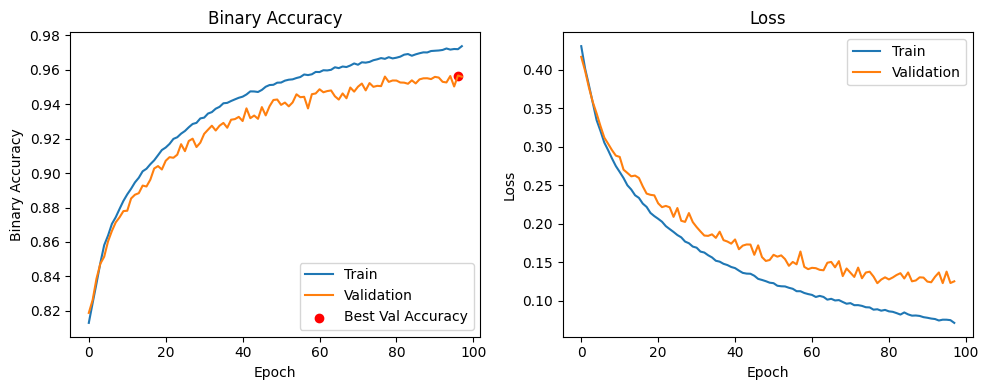

In [ ]:
# History plot
log_df = pd.read_csv('training_model_mix.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Confusion matrix for validation and test sets
model.load_weights('best_model_mix.h5')

from sklearn.metrics import multilabel_confusion_matrix

# Predict probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test, y_test_pred)

43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


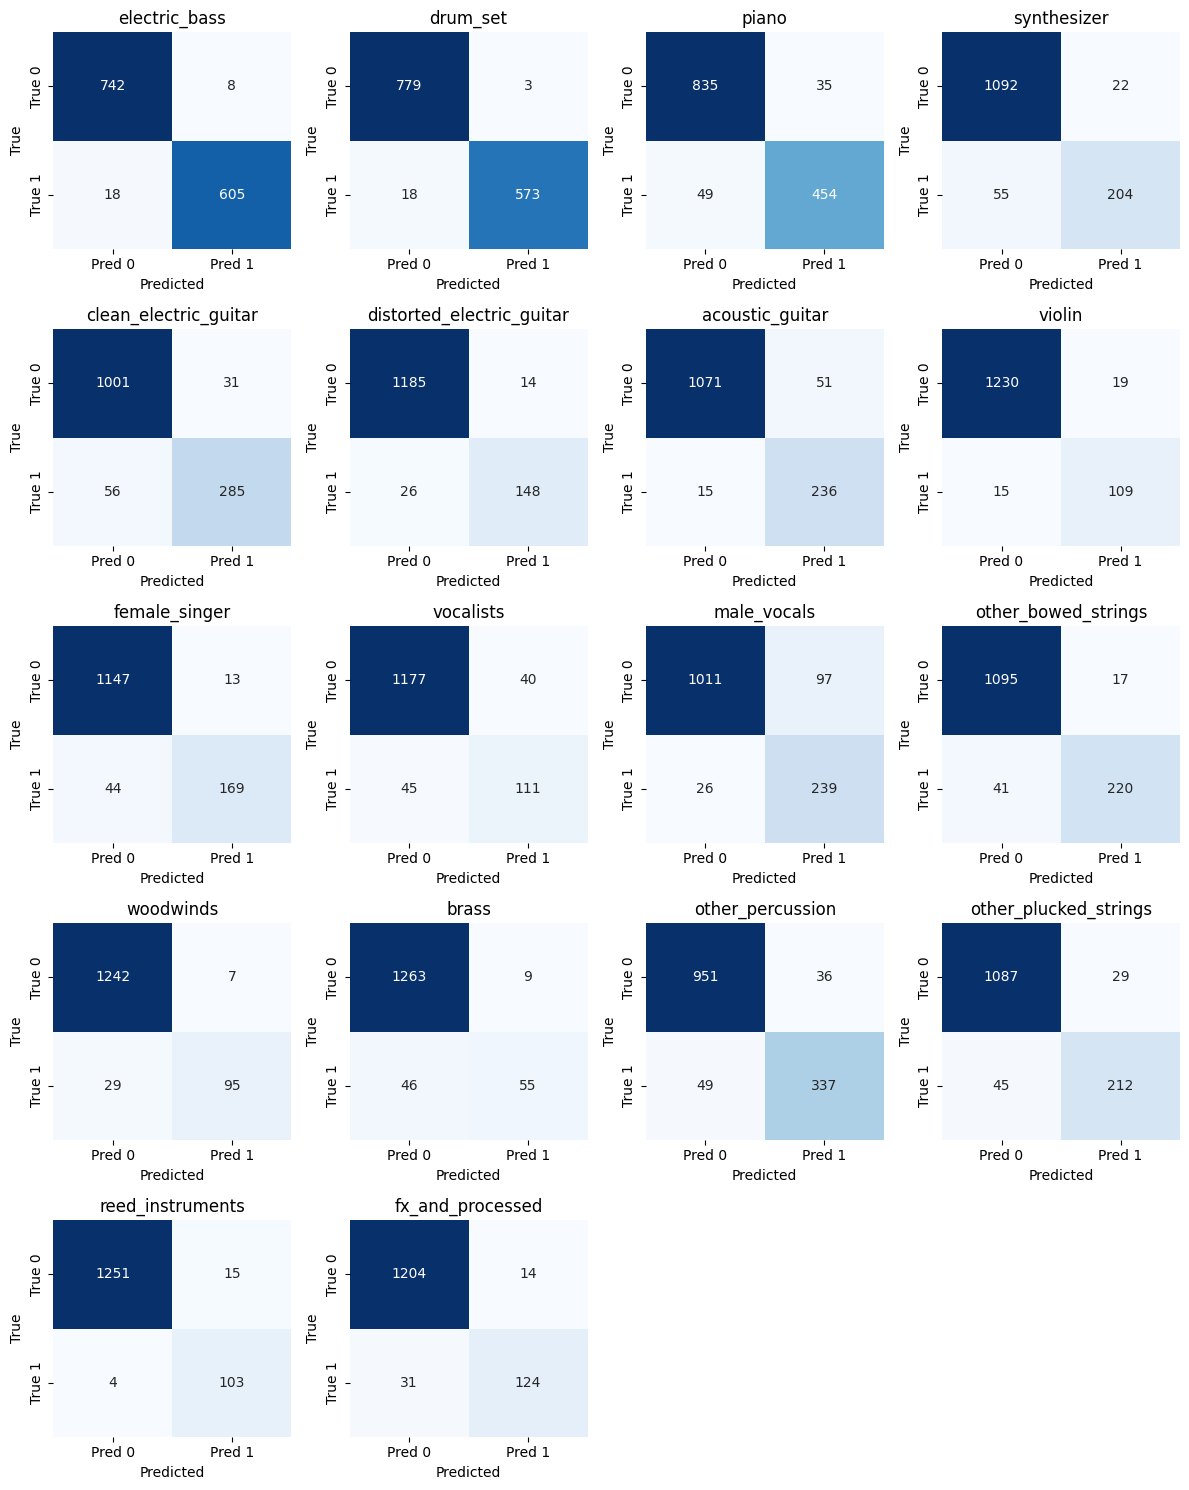

In [ ]:
num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

In [ ]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.99      0.97      0.98       623
           1       0.99      0.97      0.98       591
           2       0.93      0.90      0.92       503
           3       0.90      0.79      0.84       259
           4       0.90      0.84      0.87       341
           5       0.91      0.85      0.88       174
           6       0.82      0.94      0.88       251
           7       0.85      0.88      0.87       124
           8       0.93      0.79      0.86       213
           9       0.74      0.71      0.72       156
          10       0.71      0.90      0.80       265
          11       0.93      0.84      0.88       261
          12       0.93      0.77      0.84       124
          13       0.86      0.54      0.67       101
          14       0.90      0.87      0.89       386
          15       0.88      0.82      0.85       257
          16       0.87      0.96      0.92       107
          17       0.90    

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
